In [1]:
import sys, os
sys.path.append("../app/")

import temframe
import matplotlib.pyplot as plt
import numpy as np
import torch, pandas as pd

In [2]:
with open("O:/Nat-Tech_HGG-Projects/Projects/2025_GEM_Kenya/Data/202511/Eliye_Spring_1/Data/2025_1114/USF_Files_Eliye_Spring_1/Eliye_Spring_1_usf.zip", "rb") as f:
#with open("C:/Users/au646858/Downloads/USF_Files_dawa river.zip", "rb") as f:
    raw_df_data = temframe.TEMframe.from_zip(f.read())

forwards = raw_df_data.forward_operators
history = raw_df_data.history.copy()
sites = raw_df_data['site_id']
raw_df_data = temframe.TEMframe.from_pandas(raw_df_data[(sites>20)*(sites<40)], forward_operators=forwards, history=history)

In [3]:
# raw_df_data = raw_df_data[raw_df_data['site_id']<25]
raw_df_overview = raw_df_data.overview()

In [5]:
def silence(s):
    pass

from anemone.inversion import *

current_history = raw_df_data.history.copy()

raw_df_data.forward_operators[0].source     = raw_df_data.forward_operators[1].source
raw_df_data.forward_operators[0].receiver   = raw_df_data.forward_operators[1].receiver
raw_df_data.forward_operators[0].filterfunc = raw_df_data.forward_operators[1].filterfunc

dmfwr1 = raw_df_data.forward_operators[0]+raw_df_data.forward_operators[1]

In [34]:
with open("C:/Users/au646858/Downloads/USF_Files_dawa river.zip", "rb") as f:
    raw_df_data = temframe.TEMframe.from_zip(f.read())
raw_df_data.forward_operators[0].source     = raw_df_data.forward_operators[1].source
raw_df_data.forward_operators[0].receiver   = raw_df_data.forward_operators[1].receiver
raw_df_data.forward_operators[0].filterfunc = raw_df_data.forward_operators[1].filterfunc

dmfwr2 = raw_df_data.forward_operators[0]+raw_df_data.forward_operators[1]

In [6]:
z = torch.cumsum(torch.logspace(0, np.log10(50.), 30), 0)
z /= z.max()
z *= 150.

res_start = LogResistivity.smooth(torch.ones(len(z)+1)*10., z)
dbdt1 = dmfwr1(*res_start.mod)
# dbdt2 = dmfwr2(*res_start.mod)

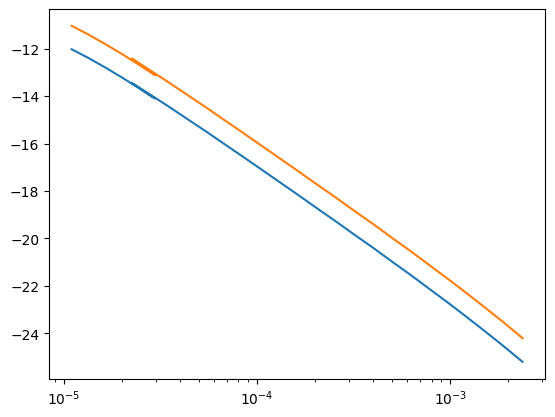

In [36]:
plt.figure()
plt.semilogx(dmfwr1.times, dbdt1)
plt.semilogx(dmfwr2.times, dbdt2+1)

In [20]:
# plt.figure()
from anemone import rdtype

df_data     = raw_df_data.copy()
df_overview = raw_df_data.overview()



df_data['include'] = df_data['inuse_manual'].astype(bool, copy=False).fillna(df_data['inuse_auto'])

df_data['dbdt_syn'] = df_data['dbdt']*np.nan
pivot_multi = df_data[(df_data['site_id']>-1)*(df_data['gate_id']>-1)].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include', 'data_id'],
)
pivot_multi['site_id'] = pivot_multi.index

pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]

assert len(pivot_multi) == len(df_overview), "Expected 4 columns in pivot_multi"

pivot_multi.sort_values(by='site_id', inplace=True)
df_overview.sort_values(by='site_id', inplace=True)        

results  = []
inv_list = []
x_list   = []
y_list   = []

for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    assert id_meta == id_row, "Site ID mismatch between row and metadata"

    dbdt_values    = row.filter(like='dbdt_').values
    error_values   = np.clip(row.filter(like='error_').values, 3, None)
    include_values = row.filter(like='include_').values
    data_id        = row.filter(like='data_id_').values
    
    d_obs = torch.from_numpy(dbdt_values).log().to(rdtype)
    # print(d_obs)
    d_err = torch.from_numpy(np.log1p(error_values/100.)).to(rdtype)
    d_err[dbdt_values <= 0] = torch.inf  # Set error to infinity for non-positive measurements
    d_obs[dbdt_values <= 0] = 0.  # Set observed data to zero for non-positive measurements
    include_mask = include_values.astype(bool)
    d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

    inv1 = fastJac(d_obs, d_err, res_start.copy(), dmfwr1.copy(), logger=print)
    inv_list.append(inv1.copy())
    x_list.append(row_meta['utm_x']*1.)
    y_list.append(row_meta['utm_y']*1.)
    # plt.semilogx(dmfwr.times, d_obs.numpy(), '-')

In [21]:
import panels

pd1 = panels.dbdtSounding(dataframe=raw_df_data)
pd1.render()

In [18]:
class Inversion(BaseInversion):
    vertical_smoothness = 0.4

    def setup_matrices(self):
        super().setup_matrices()
        self.HtH = self.model.H().T @ (self.model.H() / np.log1p(self.vertical_smoothness)**2)
        self.HtH = self.HtH.to(self.mvec.dtype)

    def calc_dm(self):
        r_data  = self.G.T @ self.Cdi @ (self.data_observed-self.data_predicted)
        r_data -= self.HtH @ self.mvec
        Aown = self.GtG + self.HtH
        return solve(Aown, r_data)

    def jacobian(self, mvec):
        rho, thick = self.model.modelize(mvec)
        G = self.forward(rho, thick, jac=True)
        G *= rho[:, None]
        G /= self.data_predicted.exp()
        return G.T

    def copy(self):
        from copy import deepcopy
        return deepcopy(self)

001	misfit:	4.93
002	misfit:	4.60
003	misfit:	4.59
004	misfit:	4.59
005	misfit:	4.59
006	misfit:	4.59
misfit change is less than 0.007
001	misfit:	5.48
002	misfit:	1.46
003	misfit:	1.07
004	misfit:	1.07
misfit change is less than 0.007
001	misfit:	6.28
002	misfit:	1.67
003	misfit:	0.84
004	misfit:	0.83
005	misfit:	0.83
006	misfit:	0.83
misfit change is less than 0.007
001	misfit:	6.92
002	misfit:	2.06
003	misfit:	0.79
004	misfit:	0.76
005	misfit:	0.76
006	misfit:	0.76
misfit change is less than 0.007


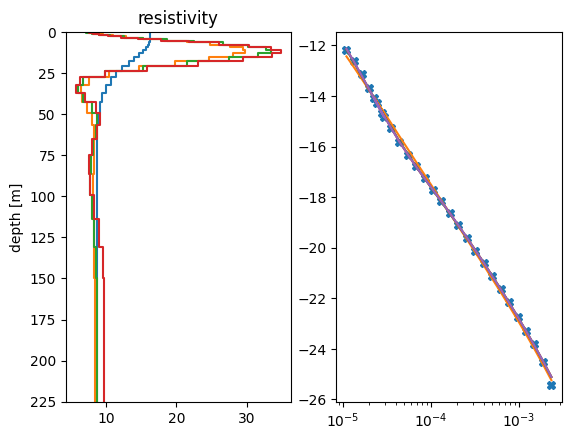

In [19]:
fig,axs = plt.subplots(1,2)
axs[1].semilogx(dmfwr1.times, d_obs.numpy(), 'X')

for _ in range(4):
    inv1 = Inversion(d_obs, d_err, res_start.copy(), dmfwr1.copy(), logger=print)
    inv1.vertical_smoothness=0.01+_*0.1
    inv1.setup_matrices()
    m1 = inv1.invert()

    m1.plot(axs=axs[:1])
    axs[1].semilogx(dmfwr1.times, inv1.data_predicted, '-')

In [22]:
sci = SCI(inv_list, x_list, y_list)
#sci = LCI(inv_list)
sci.horizontal_smoothness = 0.6
sci.vertical_smoothness   = 0.4
res_mods = sci.invert(iter_cap=10)

8  attempts  [np.float64(1.6399422336278382), np.float64(1.5817749556776777), np.float64(1.4614962193448158), np.float64(1.2510304864718174), np.float64(0.9368988006808345), np.float64(0.5654637690385724), np.float64(0.2517801119010732), np.float64(0.0803742738075627)]
dMisfit:  -0.05781389154135331
001	misfit:	576.86
data misfit:  855.2806466188152
3  attempts  [np.float64(0.026536660112429503), np.float64(0.031718803596637424), np.float64(0.0452068901940137)]
dMisfit:  -0.03256191427364899
002	misfit:	576.86
data misfit:  894.450123366749
2  attempts  [np.float64(0.01578893584891569), np.float64(0.018903095679504427)]
dMisfit:  -0.013579055187633355
003	misfit:	576.86
data misfit:  925.3329712491458
stop for repeated misfit increase


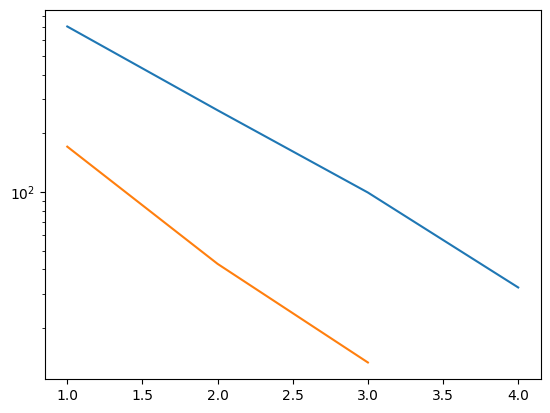

In [12]:
plt.figure()
plt.semilogy(sci.misfits)
plt.semilogy(sci.data_misfits)

In [13]:
for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    assert id_meta == id_row, "Site ID mismatch between row and metadata"

    data_id = row.filter(like='data_id_').values    
    res_mod = res_mods[i].copy()

    d_syn = inv_list[i].forward(*res_mod.mod).exp()
    df_data.loc[data_id, 'dbdt_syn'] = d_syn.numpy()

    rho,thick = res_mod.mod
    row_meta['site_id'] = id_meta
    row_meta['resistivity'] = rho.detach().cpu().numpy().tolist()
    row_meta['thickness'] = thick.detach().cpu().numpy().tolist()
    
    results.append(row_meta.to_dict())
    print(f'Inversion for data_id {i:02d} completed.', flush=True, end='\r')

df_resmod = pd.DataFrame(results)

rows = []
for _, row in df_resmod.iterrows():
    site_id = row['site_id']
    resistivities = row['resistivity']
    thicknesses = row['thickness']
    tops = np.concatenate([[0], np.cumsum(thicknesses)[:-1]])
    bottoms = np.cumsum(thicknesses)
    for i, (rho, top, bottom) in enumerate(zip(resistivities, tops, bottoms)):
        rows.append({
            'site_id': site_id,
            'daytime': row['daytime'],
            'date': row['date'],
            'latitude': row['latitude'],
            'longitude': row['longitude'],
            'elevation': row['elevation'],
            'layer': i,
            'resistivity': rho,
            'top_depth': top,
            'bottom_depth': bottom,
            'center_depth': (top + bottom) / 2
        })

df_layers = df_data.__class__(rows, history=current_history.copy())
df_data.history = current_history[:-1]

In [14]:
df_layers_long = pd.melt(
    df_layers,
    id_vars=['site_id', 'daytime', 'longitude', 'latitude', 'date', 'elevation', 'layer', 'resistivity'],
    value_vars=['top_depth', 'bottom_depth'],
    var_name='depth_type',
    value_name='depth'
).sort_values(['daytime', 'layer', 'depth'])

# Optional: drop 'depth_type' if you don't need it
df_layers_long = df_layers_long.drop(columns=['depth_type'])

df_layers_long
df_layers_long['z'] = df_layers_long['elevation']-df_layers_long['depth']
df_layers_long['log_resistivity'] = np.log10(df_layers_long['resistivity'])

In [17]:
import plotly.express as px

# Ensure all site_ids are present as columns, even if some are missing
all_site_ids = np.arange(df_layers_long['site_id'].min(), df_layers_long['site_id'].max() + 1)
heatmap_df = df_layers_long.pivot_table(
    index='depth', columns='site_id', values='log_resistivity')
heatmap_df = heatmap_df.reindex(columns=all_site_ids)

# Sort depth so it increases downward
heatmap_df = heatmap_df.sort_index(ascending=True)

try:
    fig = px.imshow(
        heatmap_df,
        aspect='auto',
        origin='lower',
        color_continuous_scale='turbo',
        labels={'x': 'Site ID', 'y': 'Depth [m]', 'color': 'log10 Resistivity [Ω·m]'},
        title='Resistivity Heatmap by Site and Depth',
        zmin=0,
        zmax=2,
    )

    fig.update_yaxes(autorange="reversed")
except ValueError as e:
    print("caught exception:", e)
fig

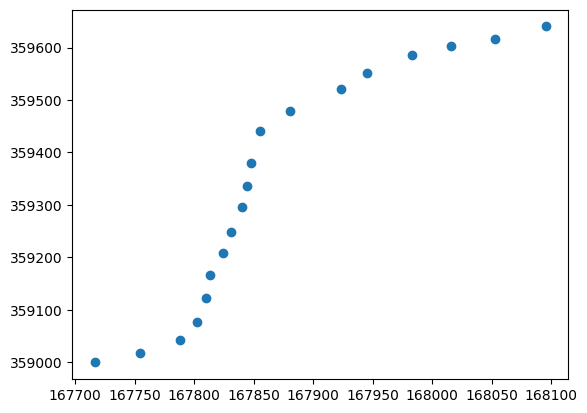

In [21]:
plt.figure()
plt.plot(x_list, y_list, 'o')